# Policy priorities within the same political self-placement

Explore differences within the Chilean participants who reported exactly 3 on the political self-placement scale. The focal proposal is Asamblea Constituyente (ID 37), with seed 101 as the principal map and seeds 201, 301, 401 and 501 for stability checks. Near, Middle and Far always refer to distance from proposal 37. They describe parts of a continuous map, not natural political classes.

**Inputs:** the supplied extracts in `data/processed/map_interpretation`, including participant IDs and original discovery/confirmation assignments, five coordinate sets, the 90 proposal positions, age decisions, proposal wording and 13,908 reserved choices. These are derived inputs from the existing age-filtered Chilean analysis, not new raw observations. Known ages below 19 were excluded and unknown ages retained. The data README documents their origins.

**Outputs:** one three-panel PDF and PNG in `outputs/figures`, with regenerated profiles, choice contrasts, bootstrap draws and stability tables in `outputs/tables/map_interpretation`.

**Run or explore:** run top to bottom in a fresh kernel from the release root or `notebooks/`. The inputs are included. No other notebook, external folder, model fitting or TensorFlow import is required. Use the environment specified in `requirements.txt`. Parameters are below. The supplied selection lock fixes the manuscript case. Changing its selection parameters may deliberately fail that check and should be treated as a separate analysis.

Discovery selects proposals and defines sector cutoffs. Confirmation describes the remaining participants and tests their reserved choices. These names preserve the original split, but the historical test data had already been consulted. This is a secondary evaluation, not a newly preregistered experiment.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display
# Accept the same two working directories as the other release notebooks.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/processed/map_interpretation"
OUT = ROOT / "outputs/tables/map_interpretation"
FIG = ROOT / "outputs/figures"
assert (DATA / "participants.csv").is_file(), "Open from the release root or notebooks/."
for directory in [OUT, FIG]:
    directory.mkdir(parents=True, exist_ok=True)
# Fixed manuscript settings. No global configuration or external helper is used.
SEEDS=[101,201,301,401,501]
FOCAL_ID=37
BOOT_SEED=20261014
N_BOOT=2000
PRIORITY_CUTOFF=30
DISTINCTIVE_GAP=10
SHARED_GAP=5
MIN_PEOPLE=30
MIN_SHARED_OPPONENTS=10
SECTORS=['Near','Middle','Far']
COLORS={'Near':'#0072B2','Middle':'#bdbdbd','Far':'#D55E00'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False})
people=pd.read_csv(DATA/'participants.csv')
assert people.uuid.is_unique and people.u.is_unique and people.politica.eq(3).all()
assert people.groupby('phase').size().to_dict()=={'confirmation':1870,'discovery':1825}
thresholds=pd.read_csv(DATA/'sector_thresholds.csv').set_index('seed')
texts=pd.read_csv(DATA/'proposal_texts.tsv',sep='\t').set_index('id')
assert texts.index.is_unique
age=pd.read_csv(DATA/'age_eligibility.csv')
assert set(age.uuid)==set(people.uuid) and age['include'].all()
coordinates = {}
proposals = {}
rankings = {}
sectors = {}
threshold_errors = []
for seed in SEEDS:
    cu=pd.read_csv(DATA/str(seed)/'coordinates.csv',float_precision='round_trip')
    cp=pd.read_csv(DATA/str(seed)/'proposals.csv',float_precision='round_trip')
    assert cu.u.tolist()==people.u.tolist() and cu.uuid.tolist()==people.uuid.tolist()
    assert cp.id.is_unique and len(cp)==90
    if seed==101: proposal_ids=cp.id.to_numpy()
    assert np.array_equal(cp.id,proposal_ids)
    coordinates[seed]=cu[['z1','z2']].to_numpy()
    proposals[seed]=cp[['z1','z2']].to_numpy()
    distances=np.linalg.norm(coordinates[seed][:,None,:]-proposals[seed][None,:,:],axis=2)
    rankings[seed]=rankdata(distances,axis=1,method='average')
    assert np.allclose(rankings[seed].sum(axis=1),90*91/2)
    focal=np.flatnonzero(proposal_ids==FOCAL_ID).item()
    learned=np.quantile(distances[people.phase.eq('discovery'),focal],[1/3,2/3])
    original=thresholds.loc[seed,['near_threshold','far_threshold']].to_numpy()
    threshold_errors.append(float(np.max(np.abs(learned-original))))
    assert threshold_errors[-1] < 1e-12
    sectors[seed]=np.where(distances[:,focal]<=original[0],'Near',np.where(distances[:,focal]>=original[1],'Far','Middle'))
people['sector101']=sectors[101]
counts=people.groupby(['phase','sector101']).size().rename('participants').reset_index()
display(counts)
counts.to_csv(OUT/'sector_counts.csv',index=False)
display(people)
people.to_csv(OUT/'participant_sectors.csv',index=False)


,phase,sector101,participants
0,confirmation,Far,617
1,confirmation,Middle,627
2,confirmation,Near,626
3,discovery,Far,609
4,discovery,Middle,608
5,discovery,Near,608


,uuid,politica,u,phase,sector101
0,000629ba-44c0-47c1-b2b2-abe4f0ee808f,3,3,discovery,Middle
1,0006b923-77a6-40c1-95e0-f98b817bcab2,3,4,discovery,Far
2,0019afe7-03fc-40b2-a8f1-6216c2943613,3,16,confirmation,Middle
3,0040473a-c6fa-4a5c-8649-2b00f72349a2,3,40,confirmation,Near
4,005d8525-7b65-49f3-8f20-9f30cc43d09c,3,60,discovery,Near
...,...,...,...,...,...
3690,ff93ecea-f070-4ba2-95b2-77e79fa2e0fe,3,47505,confirmation,Far
3691,ffb4078a-9087-4619-89c1-8a5db8f43add,3,47523,confirmation,Near
3692,ffb7699b-d817-42b5-af10-897c2cad4b94,3,47528,discovery,Middle
3693,ffd0a72e-06ee-49b3-a18c-7c2b9358870d,3,47545,confirmation,Middle


## Select proposals before reading confirmation choices

Rank all 90 proposals by Euclidean distance for each discovery participant in fit 101. Rank 1 is the highest map-inferred relative priority. Average these ranks within each sector, weighting people equally.

Always include proposal 37. Select up to two additional proposals per extreme sector with a mean rank at most 30 in that sector and an advantage of at least 10 ranks over the other extreme. Sort by the largest advantage, then the sector's mean rank and proposal ID. Select at most one remaining shared-priority proposal with both mean ranks at most 30 and an absolute difference at most 5, sorting by the smaller worst-sector mean rank, then the absolute difference and ID. Do not relax the criteria if fewer proposals qualify.

The original list was frozen before the new confirmation contrasts were calculated. Recompute it below and check its supplied hash before loading choice outcomes. Uncertain or contradictory results never trigger replacement.

In [2]:
discovery=people.phase.eq('discovery').to_numpy()
profile=pd.DataFrame({'proposal_id':proposal_ids})
for sector in SECTORS:
    mask=discovery&(sectors[101]==sector)
    profile[sector]=rankings[101][mask].mean(axis=0)
profile['gap_far_minus_near']=profile.Far-profile.Near
profile['short_name']=profile.proposal_id.map(texts.short_name)
profile['full_text']=profile.proposal_id.map(texts.name)
profile['topic']=profile.proposal_id.map(texts.topic_name)
display(profile)
profile.to_csv(OUT/'discovery_full_profile.csv',index=False)
remaining=profile[profile.proposal_id.ne(FOCAL_ID)]
near=remaining[(remaining.Near<=PRIORITY_CUTOFF)&(remaining.gap_far_minus_near>=DISTINCTIVE_GAP)].sort_values(['gap_far_minus_near','Near','proposal_id'],ascending=[False,True,True]).head(2)
far=remaining[(remaining.Far<=PRIORITY_CUTOFF)&(remaining.gap_far_minus_near<=-DISTINCTIVE_GAP)].sort_values(['gap_far_minus_near','Far','proposal_id'],ascending=[True,True,True]).head(2)
used=set(near.proposal_id)|set(far.proposal_id)|{FOCAL_ID}
shared=remaining[~remaining.proposal_id.isin(used)&(remaining.Near<=PRIORITY_CUTOFF)&(remaining.Far<=PRIORITY_CUTOFF)&(remaining.gap_far_minus_near.abs()<=SHARED_GAP)].copy()
shared['worst_rank']=shared[['Near','Far']].max(axis=1)
shared['absolute_gap']=shared.gap_far_minus_near.abs()
shared=shared.sort_values(['worst_rank','absolute_gap','proposal_id']).head(1)
selected=pd.concat([profile[profile.proposal_id.eq(FOCAL_ID)].assign(role='Focal'),near.assign(role='Near-distinctive'),far.assign(role='Far-distinctive'),shared[profile.columns].assign(role='Shared')],ignore_index=True)
selected.insert(0,'figure_number',np.arange(1,len(selected)+1))
assert selected.proposal_id.is_unique and len(selected)<=6
payload=selected.to_csv(index=False)
# This read-only lock preserves the original discovery-only selection.
lock = DATA / "selection_lock.json"
selection_lock = json.loads(lock.read_text())
assert selection_lock["selection_sha256"] == hashlib.sha256(payload.encode()).hexdigest(), "Frozen selection changed."
assert selection_lock["ids"] == selected.proposal_id.tolist()
assert selection_lock["protocol_sha256"] == hashlib.sha256((DATA / "selection_protocol.md").read_bytes()).hexdigest()
display(selected)
(OUT/'selected_proposals.csv').write_text(payload)


Out[2]: 1113


,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic
0,1,36.146382,38.542763,38.359606,2.213224,Farmacias,Creación de Farmacias Populares,Salud
1,2,77.271382,81.172697,85.022989,7.751607,Marihuana,Legalización de la Marihuana,Salud
2,3,19.805921,14.585526,13.706076,-6.099846,Cárcel Cohecho,Cárcel Efectiva para Soborno y Cohecho,Política Criminal
3,4,16.258224,27.139803,47.339901,31.081678,Retiro AFP,Retiro Anticipado Fondo de Pensiones,Pensiones
4,5,80.430921,74.654605,57.919540,-22.511381,Más Metro,Crear Nuevas Líneas de Metro,Vivienda y Transporte
...,...,...,...,...,...,...,...,...
85,86,5.870066,11.281250,39.977011,34.106946,CAE,Condonación de las deudas del Crédito con Aval...,Educación
86,87,24.286184,19.625000,14.709360,-9.576825,Sueldo Mínimo,Aumentar el Sueldo Mínimo,Laboral
87,88,6.159539,23.746711,61.133005,54.973465,Plebiscitos Nacionales,Habilitar plebiscitos nacionales.,Democracia
88,89,56.054276,48.807566,37.264368,-18.789908,Autonomía Regional,Entregar más autonomía a las regiones en su go...,Modernización del Estado


,figure_number,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic,role
0,1,37,2.898026,21.162829,66.428571,63.530545,Asamblea Constituyente,Asamblea Constituyente,Modernización del Estado,Focal
1,2,72,12.942434,52.784539,85.072250,72.129815,Provincias,Reducir Número de Provincias,Modernización del Estado,Near-distinctive
2,3,57,4.205592,25.148026,67.334975,63.129383,Derechos Humanos,Investigación Judicial de Violaciones Reciente...,Política Criminal,Near-distinctive
3,4,78,49.156250,42.449013,29.295567,-19.860683,Sistema Electoral,Eliminación de elección de parlamentarios por ...,Democracia,Far-distinctive
4,5,66,46.271382,39.625000,28.655172,-17.616209,Elección Parlamentarios,Limitar la Reeleción de Parlamentarios y Parla...,Democracia,Far-distinctive
5,6,55,14.723684,9.026316,12.359606,-2.364078,Pensión Mínima,Pensión Mínima Igual o Mayor al Sueldo Mínimo,Pensiones,Shared


## Proposal wording and complete priority profiles

The source `name` field is the full wording available in the supplied proposal file. It is not an extended legal description. English figure labels retain that scope.

For confirmation participants, keep the distance cutoffs learned in discovery. Panel B uses mean inferred ranks for these people, with equal weight per person. Proposal selection is already fixed.

First compare the same people and seed-101 sectors across all five maps. Then assign sectors using each fit's original discovery cutoffs. This separates geometric variation from changes in sector membership.

In [3]:
figure_labels=pd.read_csv(DATA/'figure_labels.csv').set_index('proposal_id')
assert set(selected.proposal_id)==set(figure_labels.index)
selected['figure_label']=selected.proposal_id.map(figure_labels.figure_label)
text_table=selected[['figure_number','proposal_id','role','full_text','figure_label']].copy()
display(text_table)
text_table.to_csv(OUT/'selected_source_texts.csv',index=False)
profile_rows=[]
for seed in SEEDS:
    for membership in ['Fixed 101 sectors','Seed-specific sectors']:
        group=sectors[101] if membership=='Fixed 101 sectors' else sectors[seed]
        for phase in ['discovery','confirmation']:
            for sector in SECTORS:
                mask=people.phase.eq(phase).to_numpy()&(group==sector)
                means=rankings[seed][mask].mean(axis=0)
                for proposal_id,mean in zip(proposal_ids,means):
                    profile_rows.append({'seed':seed,'membership':membership,'phase':phase,'sector':sector,'proposal_id':proposal_id,'mean_rank':mean,'n_people':int(mask.sum())})
profiles=pd.DataFrame(profile_rows)
display(profiles)
profiles.to_csv(OUT/'complete_90_proposal_profiles.csv',index=False)
gaps=profiles.pivot(index=['seed','membership','phase','proposal_id'],columns='sector',values='mean_rank').reset_index()
gaps['gap_far_minus_near']=gaps.Far-gaps.Near
selected_gaps=gaps[gaps.proposal_id.isin(selected.proposal_id)].merge(selected[['proposal_id','role','figure_number']],on='proposal_id',validate='many_to_one').sort_values(['membership','phase','figure_number','seed'])
display(selected_gaps)
selected_gaps.to_csv(OUT/'selected_profile_stability.csv',index=False)
assignments=people[['u','uuid','phase']].copy()
for seed in SEEDS:assignments[f'sector_{seed}']=sectors[seed]
display(assignments)
assignments.to_csv(OUT/'sector_memberships.csv',index=False)
transition_rows=[];agreement_rows=[]
for phase in ['discovery','confirmation']:
    mask=people.phase.eq(phase).to_numpy()
    for seed in SEEDS:
        for old in SECTORS:
            for new in SECTORS:
                transition_rows.append({'phase':phase,'seed':seed,'sector101':old,'sector_other':new,'n_people':int(np.sum(mask&(sectors[101]==old)&(sectors[seed]==new)))})
        row={'phase':phase,'seed':seed,'same_sector_fraction':np.mean(sectors[101][mask]==sectors[seed][mask])}
        for sector in SECTORS:
            a=sectors[101][mask]==sector;b=sectors[seed][mask]==sector
            row[f'jaccard_{sector.lower()}']=np.sum(a&b)/np.sum(a|b)
        row['opposite_extreme_fraction']=np.mean(((sectors[101][mask]=='Near')&(sectors[seed][mask]=='Far'))|((sectors[101][mask]=='Far')&(sectors[seed][mask]=='Near')))
        agreement_rows.append(row)
transitions=pd.DataFrame(transition_rows);agreement=pd.DataFrame(agreement_rows)
for obj,name in [(transitions,'sector_transitions'),(agreement,'sector_agreement')]:
    display(obj)
    obj.to_csv(OUT/(name+'.csv'),index=False)


,figure_number,proposal_id,role,full_text,figure_label
0,1,37,Focal,Asamblea Constituyente,Constituent assembly
1,2,72,Near-distinctive,Reducir Número de Provincias,Reduce number of provinces
2,3,57,Near-distinctive,Investigación Judicial de Violaciones Reciente...,Investigate recent human-rights violations
3,4,78,Far-distinctive,Eliminación de elección de parlamentarios por ...,End coattail-based election of legislators
4,5,66,Far-distinctive,Limitar la Reeleción de Parlamentarios y Parla...,Limit parliamentary reelection
5,6,55,Shared,Pensión Mínima Igual o Mayor al Sueldo Mínimo,Minimum pension at least the minimum wage


,seed,membership,phase,sector,proposal_id,mean_rank,n_people
0,101,Fixed 101 sectors,discovery,Near,1,36.146382,608
1,101,Fixed 101 sectors,discovery,Near,2,77.271382,608
2,101,Fixed 101 sectors,discovery,Near,3,19.805921,608
3,101,Fixed 101 sectors,discovery,Near,4,16.258224,608
4,101,Fixed 101 sectors,discovery,Near,5,80.430921,608
...,...,...,...,...,...,...,...
5395,501,Seed-specific sectors,confirmation,Far,86,43.419458,627
5396,501,Seed-specific sectors,confirmation,Far,87,18.110048,627
5397,501,Seed-specific sectors,confirmation,Far,88,66.216906,627
5398,501,Seed-specific sectors,confirmation,Far,89,28.074960,627


,seed,membership,phase,proposal_id,Far,Middle,Near,gap_far_minus_near,role,figure_number
0,101,Fixed 101 sectors,confirmation,37,68.669368,21.649123,2.857827,65.811540,Focal,1
24,201,Fixed 101 sectors,confirmation,37,57.687196,23.011164,6.138978,51.548218,Focal,1
48,301,Fixed 101 sectors,confirmation,37,60.090762,19.944179,4.468051,55.622711,Focal,1
72,401,Fixed 101 sectors,confirmation,37,55.188006,24.848485,11.012780,44.175227,Focal,1
96,501,Fixed 101 sectors,confirmation,37,52.653160,22.614035,7.932907,44.720253,Focal,1
...,...,...,...,...,...,...,...,...,...,...
19,101,Seed-specific sectors,discovery,55,12.359606,9.026316,14.723684,-2.364078,Shared,6
43,201,Seed-specific sectors,discovery,55,10.407225,8.233937,9.361248,1.045977,Shared,6
67,301,Seed-specific sectors,discovery,55,11.599343,7.774300,9.724138,1.875205,Shared,6
91,401,Seed-specific sectors,discovery,55,15.870279,9.820724,15.777961,0.092319,Shared,6


,u,uuid,phase,sector_101,sector_201,sector_301,sector_401,sector_501
0,3,000629ba-44c0-47c1-b2b2-abe4f0ee808f,discovery,Middle,Far,Far,Far,Far
1,4,0006b923-77a6-40c1-95e0-f98b817bcab2,discovery,Far,Far,Far,Far,Far
2,16,0019afe7-03fc-40b2-a8f1-6216c2943613,confirmation,Middle,Near,Near,Near,Near
3,40,0040473a-c6fa-4a5c-8649-2b00f72349a2,confirmation,Near,Near,Near,Middle,Near
4,60,005d8525-7b65-49f3-8f20-9f30cc43d09c,discovery,Near,Near,Middle,Far,Far
...,...,...,...,...,...,...,...,...
3690,47505,ff93ecea-f070-4ba2-95b2-77e79fa2e0fe,confirmation,Far,Far,Far,Far,Far
3691,47523,ffb4078a-9087-4619-89c1-8a5db8f43add,confirmation,Near,Middle,Middle,Middle,Far
3692,47528,ffb7699b-d817-42b5-af10-897c2cad4b94,discovery,Middle,Far,Far,Middle,Far
3693,47545,ffd0a72e-06ee-49b3-a18c-7c2b9358870d,confirmation,Middle,Near,Middle,Middle,Near


,phase,seed,sector101,sector_other,n_people
0,discovery,101,Near,Near,608
1,discovery,101,Near,Middle,0
2,discovery,101,Near,Far,0
3,discovery,101,Middle,Near,0
4,discovery,101,Middle,Middle,608
...,...,...,...,...,...
85,confirmation,501,Middle,Middle,312
86,confirmation,501,Middle,Far,153
87,confirmation,501,Far,Near,24
88,confirmation,501,Far,Middle,144


,phase,seed,same_sector_fraction,jaccard_near,jaccard_middle,jaccard_far,opposite_extreme_fraction
0,discovery,101,1.000000,1.000000,1.000000,1.000000,0.000000
1,discovery,201,0.642192,0.493252,0.339581,0.611111,0.029589
2,discovery,301,0.654247,0.540506,0.354515,0.583875,0.028493
3,discovery,401,0.633973,0.504950,0.327511,0.583875,0.028493
4,discovery,501,0.632329,0.506815,0.321739,0.583875,0.025753
5,confirmation,101,1.000000,1.000000,1.000000,1.000000,0.000000
6,confirmation,201,0.629412,0.495025,0.326157,0.573494,0.035829
7,confirmation,301,0.670588,0.548428,0.364333,0.624196,0.018717
8,confirmation,401,0.636364,0.508663,0.342524,0.570713,0.032086
9,confirmation,501,0.644920,0.548030,0.336570,0.564780,0.026203


## Observed choices outside model training

Estimate the near-minus-far difference using a linear probability model with opposing-proposal fixed effects. The middle sector remains visible on the map but does not enter this contrast. The function below subtracts opponent-specific means, which yields the same coefficient as explicitly fitting opponent indicators.

For each of 2,000 bootstrap replicates, resample participants and weight all their choices by their sampled multiplicity. Recompute the opponent means and coefficient with those weights. Report the 2.5th and 97.5th percentiles. Intervals are pointwise, conditional on the fitted map and fixed sectors, and are not adjusted for multiple comparisons.

Report participants, choices and common support. The specified support threshold is at least 30 people in each extreme and 10 opponents seen in both extremes. Opponents observed in only one sector do not identify the adjusted contrast. Keep uncertain and contradictory estimates visible. These differences are associations, not causal effects of map location.

In [4]:
def adjusted_effect(frame,bootstrap=0,seed=BOOT_SEED):
    # Partial out opponent fixed effects by subtracting each opponent's mean.
    opp,oi=np.unique(frame.opponent,return_inverse=True)
    us,ui_local=np.unique(frame.u,return_inverse=True)
    x=frame.near.to_numpy(float); y=frame.chosen.to_numpy(float)
    n=np.bincount(oi); sx=np.bincount(oi,weights=x); sy=np.bincount(oi,weights=y)
    mixed=(sx>0)&(sx<n)
    xr=x-sx[oi]/n[oi];yr=y-sy[oi]/n[oi]
    denominator=xr@xr
    beta=float(xr@yr/denominator) if denominator>0 else np.nan
    influence=np.bincount(ui_local,weights=xr*(yr-beta*xr),minlength=len(us))
    se=float(np.sqrt((influence@influence)*len(us)/(len(us)-1))/denominator) if denominator>0 and len(us)>1 else np.nan
    result={'difference':beta,'cluster_se':se,'z':beta/se,'n_rows':len(frame),'n_users':len(us),'near_users':frame.loc[frame.near.eq(1),'u'].nunique(),'far_users':frame.loc[frame.near.eq(0),'u'].nunique(),'shared_opponents':int(mixed.sum()),'overlap_rows':int(n[mixed].sum()),'raw_near_rate':float(y[x==1].mean()),'raw_far_rate':float(y[x==0].mean())}
    draws=[]
    if bootstrap:
        rng=np.random.default_rng(seed)
        # Each sampled person's multiplicity weights every one of their choices.
        for b in range(bootstrap):
            multiplicities=rng.multinomial(len(us),np.repeat(1/len(us),len(us)))
            w=multiplicities[ui_local]
            nw=np.bincount(oi,weights=w,minlength=len(opp))
            sxw=np.bincount(oi,weights=w*x,minlength=len(opp))
            syw=np.bincount(oi,weights=w*y,minlength=len(opp))
            sxyw=np.bincount(oi,weights=w*x*y,minlength=len(opp))
            valid=nw>0
            denom=np.sum(sxw[valid]-sxw[valid]**2/nw[valid])
            num=np.sum(sxyw[valid]-sxw[valid]*syw[valid]/nw[valid])
            draws.append(num/denom if denom>0 else np.nan)
        assert np.isfinite(draws).all()
        result['lower95'],result['upper95']=np.quantile(draws,[.025,.975])
    return result,np.asarray(draws)

choices=pd.read_parquet(DATA/'confirmation_choices.parquet')
assert choices.id.is_unique and len(choices)==13908
assert choices.label.eq(3).all() and choices.phase.eq('confirmation').all()
assert set(choices.u)==set(people.loc[people.phase.eq('confirmation'),'u'])
assert np.all(np.where(choices.y.eq(1),choices.option_a,choices.option_b)==choices.selected)
assert np.all(proposal_ids[choices.a.to_numpy()]==choices.option_a)
assert np.all(proposal_ids[choices.b.to_numpy()]==choices.option_b)
assert not choices.assign(lo=np.minimum(choices.a,choices.b),hi=np.maximum(choices.a,choices.b)).duplicated(['u','lo','hi']).any()
sector_by_user=people.set_index('u').sector101
choices['sector']=choices.u.map(sector_by_user)
observed_rows=[];bootstrap_rows=[];analysis_frames=[];support_rows=[]
for row in selected.itertuples():
    f=choices[(choices.option_a.eq(row.proposal_id)|choices.option_b.eq(row.proposal_id))&choices.sector.isin(['Near','Far'])].copy()
    f['near']=f.sector.eq('Near').astype(int)
    f['opponent']=np.where(f.option_a.eq(row.proposal_id),f.b,f.a)
    f['chosen']=f.selected.eq(row.proposal_id).astype(int)
    effect,draws=adjusted_effect(f,N_BOOT)
    effect.update({'proposal_id':row.proposal_id,'figure_number':row.figure_number,'role':row.role,'figure_label':row.figure_label})
    effect['sufficient_support']=effect['near_users']>=MIN_PEOPLE and effect['far_users']>=MIN_PEOPLE and effect['shared_opponents']>=MIN_SHARED_OPPONENTS
    effect['common_support_fraction']=effect['overlap_rows']/effect['n_rows']
    observed_rows.append(effect)
    bootstrap_rows.append(pd.DataFrame({'proposal_id':row.proposal_id,'replicate':np.arange(N_BOOT),'difference':draws}))
    analysis_frames.append(f.assign(target_id=row.proposal_id))
    support=f.groupby(['opponent','sector']).agg(rows=('id','size'),people=('u','nunique')).reset_index()
    support['target_id']=row.proposal_id
    support_rows.append(support)
observed=pd.DataFrame(observed_rows).sort_values('figure_number')
bootstraps=pd.concat(bootstrap_rows,ignore_index=True)
support=pd.concat(support_rows,ignore_index=True)
analysis_choices=pd.concat(analysis_frames,ignore_index=True)
for obj,name in [(observed,'observed_choice_differences'),(bootstraps,'bootstrap_replicates'),(support,'opponent_support')]:
    display(obj)
    obj.to_csv(OUT/(name+'.csv'),index=False)
display(analysis_choices)
analysis_choices.to_parquet(OUT/'selected_confirmation_choices.parquet',index=False)
# The fixed focal contrast must reproduce the previously verified analysis.
focal_check=observed[observed.proposal_id.eq(37)].iloc[0]
assert abs(focal_check.difference-0.324007)<1e-6
assert abs(focal_check.lower95-0.152848)<1e-6
assert abs(focal_check.upper95-0.486768)<1e-6


,difference,cluster_se,z,n_rows,n_users,near_users,far_users,shared_opponents,overlap_rows,raw_near_rate,raw_far_rate,lower95,upper95,proposal_id,figure_number,role,figure_label,sufficient_support,common_support_fraction
0,0.324007,0.058782,5.512040,219,200,123,77,45,145,0.901515,0.586207,0.152848,0.486768,37,1,Focal,Constituent assembly,True,0.662100
1,-0.115707,0.049816,-2.322697,223,187,131,56,42,148,0.141935,0.220588,-0.244993,0.029863,72,2,Near-distinctive,Reduce number of provinces,True,0.663677
2,0.230899,0.057202,4.036593,239,212,126,86,48,182,0.794521,0.559140,0.071146,0.365411,57,3,Near-distinctive,Investigate recent human-rights violations,True,0.761506
3,-0.115548,0.067614,-1.708944,227,192,103,89,48,150,0.504065,0.625000,-0.309773,0.075483,78,4,Far-distinctive,End coattail-based election of legislators,True,0.660793
4,-0.099041,0.076272,-1.298526,205,183,113,70,41,139,0.463415,0.548780,-0.308090,0.118126,66,5,Far-distinctive,Limit parliamentary reelection,True,0.678049
5,-0.006955,0.049751,-0.139803,250,217,137,80,50,183,0.840764,0.752688,-0.131634,0.131973,55,6,Shared,Minimum pension at least the minimum wage,True,0.732000


,proposal_id,replicate,difference
0,37,0,0.318153
1,37,1,0.386687
2,37,2,0.368322
3,37,3,0.211205
4,37,4,0.501112
...,...,...,...
11995,55,1995,0.094810
11996,55,1996,0.044670
11997,55,1997,0.077439
11998,55,1998,-0.015868


,opponent,sector,rows,people,target_id
0,0,Far,1,1,37
1,0,Near,1,1,37
2,1,Near,1,1,37
3,2,Far,1,1,37
4,3,Near,1,1,37
...,...,...,...,...,...
767,87,Far,1,1,55
768,87,Near,3,3,55
769,88,Far,2,2,55
770,89,Far,1,1,55


,id,uuid,u,option_a,option_b,selected,a,b,y,label,phase,sector,near,opponent,chosen,target_id
0,20304,85defd8b-8a5d-419d-8a4c-7cb09b83bb36,24873,37,34,34,36,33,0,3,confirmation,Far,0,33,0,37
1,20537,85defd8b-8a5d-419d-8a4c-7cb09b83bb36,24873,70,37,70,69,36,1,3,confirmation,Far,0,69,0,37
2,27304,5cc479bf-c2fe-4d6d-9343-aa05e9b843f2,17259,19,37,37,18,36,0,3,confirmation,Near,1,18,1,37
3,40992,30ddf8fa-02d6-454d-9e20-cdaffb2658a5,9136,31,37,37,30,36,0,3,confirmation,Near,1,30,1,37
4,57401,5c3712af-afeb-48a0-a339-f4075f524fa6,17151,84,37,37,83,36,0,3,confirmation,Near,1,83,1,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1358,3573309,d7d38b84-f0b6-4907-845e-e552ada93f8c,40115,35,55,55,34,54,0,3,confirmation,Near,1,34,1,55
1359,3579858,a797bf7f-d6a7-4e7d-a4f8-40e76855aaf2,31169,55,6,55,54,5,1,3,confirmation,Near,1,5,1,55
1360,3590944,baa3583f-c27c-4a73-a243-edc6537543d7,34720,55,54,55,54,53,1,3,confirmation,Near,1,53,1,55
1361,3605626,5fdcee9c-2f94-45ba-a0ad-478c502cf3ca,17842,84,55,55,83,54,0,3,confirmation,Near,1,83,1,55


## Stability across five fits

A positive rank gap means higher inferred relative priority in the near sector. The main check holds seed-101 membership fixed. Also report results using each fit's own sectors, without replacing proposals. The fits share training data and are not five independent samples.

In [5]:
stability_rows=[]
for (membership,phase,proposal_id),g in selected_gaps.groupby(['membership','phase','proposal_id']):
    original=selected.set_index('proposal_id').loc[proposal_id]
    direction=np.sign(original.gap_far_minus_near)
    same_sign=int((np.sign(g.gap_far_minus_near)==direction).sum())
    stability_rows.append({'membership':membership,'phase':phase,'proposal_id':proposal_id,'role':original.role,'positive_gap_fits':int(g.gap_far_minus_near.gt(0).sum()),'same_discovery_direction_fits':same_sign,'min_gap':g.gap_far_minus_near.min(),'max_gap':g.gap_far_minus_near.max(),'near_priority_top30_fits':int(g.Near.le(PRIORITY_CUTOFF).sum()),'far_priority_top30_fits':int(g.Far.le(PRIORITY_CUTOFF).sum()),'shared_rule_fits':int((g.Near.le(PRIORITY_CUTOFF)&g.Far.le(PRIORITY_CUTOFF)&g.gap_far_minus_near.abs().le(SHARED_GAP)).sum())})
stability=pd.DataFrame(stability_rows)
display(stability)
stability.to_csv(OUT/'interpretation_stability.csv',index=False)


,membership,phase,proposal_id,role,positive_gap_fits,same_discovery_direction_fits,min_gap,max_gap,near_priority_top30_fits,far_priority_top30_fits,shared_rule_fits
0,Fixed 101 sectors,confirmation,37,Focal,5,5,44.175227,65.811540,5,0,0
1,Fixed 101 sectors,confirmation,55,Shared,4,1,-1.696685,3.895291,5,5,5
2,Fixed 101 sectors,confirmation,57,Near-distinctive,5,5,44.102658,63.950150,5,0,0
3,Fixed 101 sectors,confirmation,66,Far-distinctive,0,5,-15.701703,-12.645696,0,0,0
4,Fixed 101 sectors,confirmation,72,Near-distinctive,2,2,-6.102552,72.796695,1,0,0
5,Fixed 101 sectors,confirmation,78,Far-distinctive,0,5,-19.004922,-12.571647,0,1,0
6,Fixed 101 sectors,discovery,37,Focal,5,5,43.310077,63.530545,5,0,0
7,Fixed 101 sectors,discovery,55,Shared,2,3,-2.364078,2.115915,5,5,5
8,Fixed 101 sectors,discovery,57,Near-distinctive,5,5,43.212668,63.129383,5,0,0
9,Fixed 101 sectors,discovery,66,Far-distinctive,0,5,-17.616209,-12.943744,0,1,0


## Main figure

A shows confirmation participants with self-placement 3 and the six selected proposals. B shows map-inferred mean priority ranks for the same people and sectors. C shows observed choice differences adjusted for the opposing proposal. Numbers identify the same proposals in every panel.

Near and Far remain defined relative to proposal 37 for every comparison. Similar inferred ranks in B do not establish equivalent observed choice rates or political consensus.

,uuid,politica,u,phase,sector101,x,y
2,0019afe7-03fc-40b2-a8f1-6216c2943613,3,16,confirmation,Middle,0.682774,0.394901
3,0040473a-c6fa-4a5c-8649-2b00f72349a2,3,40,confirmation,Near,0.688026,0.205364
8,00b2ad71-54f2-4896-b3fc-bad40a08fe6b,3,115,confirmation,Far,0.340295,0.097426
9,00b82471-4736-4ec8-9168-0492d8c29702,3,121,confirmation,Near,0.773233,0.108338
10,00bfca46-fcf5-4202-8bfd-bc9b40831137,3,126,confirmation,Far,0.344372,0.330950
...,...,...,...,...,...,...,...
3689,ff87a993-0ec8-4048-9141-6955db00a583,3,47494,confirmation,Middle,0.563483,0.363470
3690,ff93ecea-f070-4ba2-95b2-77e79fa2e0fe,3,47505,confirmation,Far,0.195801,0.265283
3691,ffb4078a-9087-4619-89c1-8a5db8f43add,3,47523,confirmation,Near,0.593364,0.196528
3693,ffd0a72e-06ee-49b3-a18c-7c2b9358870d,3,47545,confirmation,Middle,0.422893,0.174609


,proposal_id,figure_number,figure_label,x,y
0,37,1,Constituent assembly,0.793352,8.392607e-02
1,72,2,Reduce number of provinces,1.000000,1.551061e-09
2,57,3,Investigate recent human-rights violations,0.862272,2.442137e-01
3,78,4,End coattail-based election of legislators,0.126733,4.251936e-01
4,66,5,Limit parliamentary reelection,0.115664,3.644267e-01
5,55,6,Minimum pension at least the minimum wage,0.332946,3.299103e-01


,seed,membership,phase,sector,proposal_id,mean_rank,n_people,figure_number,role,figure_label
0,101,Fixed 101 sectors,confirmation,Near,37,2.857827,626,1,Focal,Constituent assembly
1,101,Fixed 101 sectors,confirmation,Near,55,14.793930,626,6,Shared,Minimum pension at least the minimum wage
2,101,Fixed 101 sectors,confirmation,Near,57,4.249201,626,3,Near-distinctive,Investigate recent human-rights violations
3,101,Fixed 101 sectors,confirmation,Near,66,46.116613,626,5,Far-distinctive,Limit parliamentary reelection
4,101,Fixed 101 sectors,confirmation,Near,72,13.062300,626,2,Near-distinctive,Reduce number of provinces
5,101,Fixed 101 sectors,confirmation,Near,78,49.107029,626,4,Far-distinctive,End coattail-based election of legislators
6,101,Fixed 101 sectors,confirmation,Middle,37,21.649123,627,1,Focal,Constituent assembly
7,101,Fixed 101 sectors,confirmation,Middle,55,9.441786,627,6,Shared,Minimum pension at least the minimum wage
8,101,Fixed 101 sectors,confirmation,Middle,57,24.636364,627,3,Near-distinctive,Investigate recent human-rights violations
9,101,Fixed 101 sectors,confirmation,Middle,66,40.859649,627,5,Far-distinctive,Limit parliamentary reelection


,difference,cluster_se,z,n_rows,n_users,near_users,far_users,shared_opponents,overlap_rows,raw_near_rate,raw_far_rate,lower95,upper95,proposal_id,figure_number,role,figure_label,sufficient_support,common_support_fraction
0,0.324007,0.058782,5.512040,219,200,123,77,45,145,0.901515,0.586207,0.152848,0.486768,37,1,Focal,Constituent assembly,True,0.662100
1,-0.115707,0.049816,-2.322697,223,187,131,56,42,148,0.141935,0.220588,-0.244993,0.029863,72,2,Near-distinctive,Reduce number of provinces,True,0.663677
2,0.230899,0.057202,4.036593,239,212,126,86,48,182,0.794521,0.559140,0.071146,0.365411,57,3,Near-distinctive,Investigate recent human-rights violations,True,0.761506
3,-0.115548,0.067614,-1.708944,227,192,103,89,48,150,0.504065,0.625000,-0.309773,0.075483,78,4,Far-distinctive,End coattail-based election of legislators,True,0.660793
4,-0.099041,0.076272,-1.298526,205,183,113,70,41,139,0.463415,0.548780,-0.308090,0.118126,66,5,Far-distinctive,Limit parliamentary reelection,True,0.678049
5,-0.006955,0.049751,-0.139803,250,217,137,80,50,183,0.840764,0.752688,-0.131634,0.131973,55,6,Shared,Minimum pension at least the minimum wage,True,0.732000


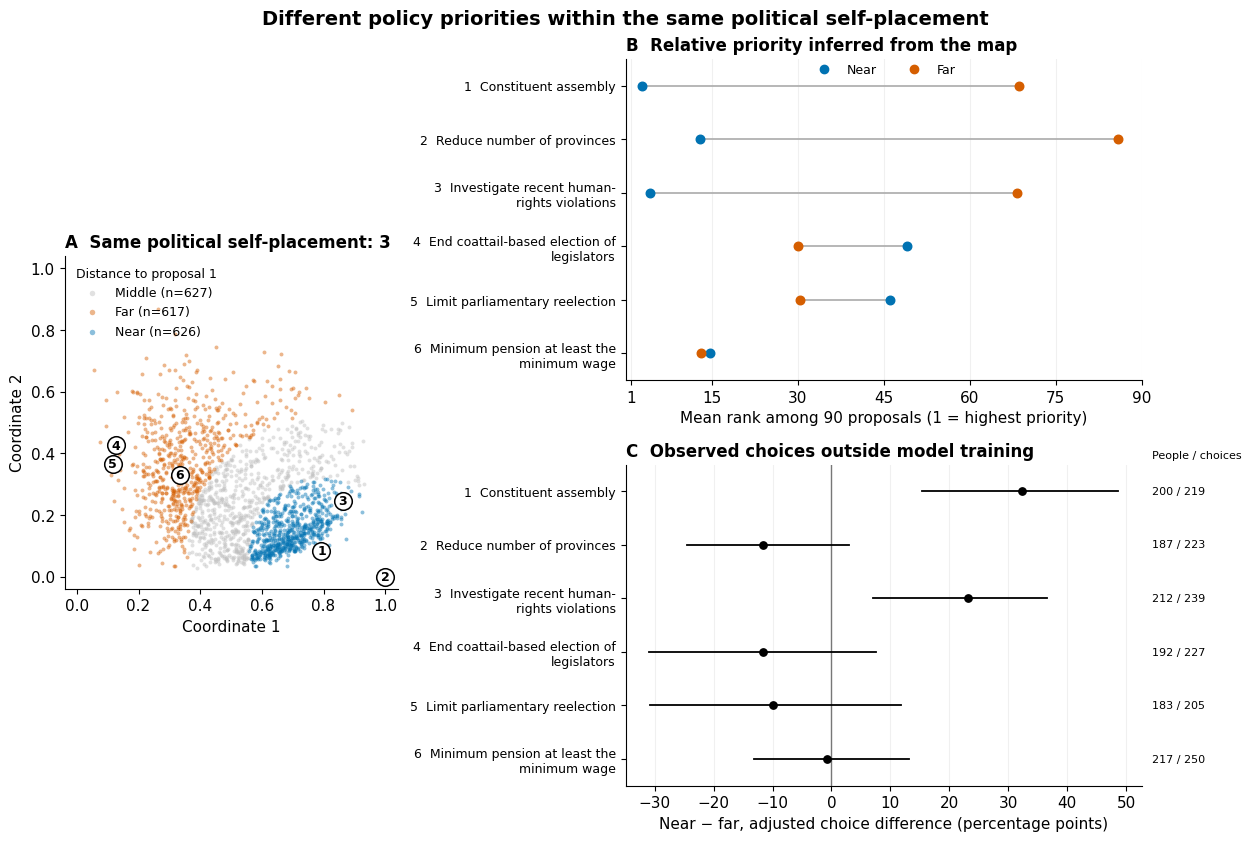

In [6]:
from matplotlib.lines import Line2D
import textwrap
plot_people=people[people.phase.eq('confirmation')].copy()
index=people.index[people.phase.eq('confirmation')].to_numpy()
plot_people['x']=coordinates[101][index,1]
plot_people['y']=coordinates[101][index,0]
plot_profiles=profiles[(profiles.seed.eq(101))&(profiles.membership.eq('Fixed 101 sectors'))&(profiles.phase.eq('confirmation'))&(profiles.proposal_id.isin(selected.proposal_id))].merge(selected[['proposal_id','figure_number','role','figure_label']],on='proposal_id',validate='many_to_one')
plot_proposals=selected[['proposal_id','figure_number','figure_label']].copy()
plot_proposals['x']=[proposals[101][np.flatnonzero(proposal_ids==i).item(),1] for i in plot_proposals.proposal_id]
plot_proposals['y']=[proposals[101][np.flatnonzero(proposal_ids==i).item(),0] for i in plot_proposals.proposal_id]
for obj,name in [(plot_people,'panel_a_participants'),(plot_proposals,'panel_a_proposals'),(plot_profiles,'panel_b_rankings'),(observed,'panel_c_choices')]:
    display(obj)
    obj.to_csv(OUT/(name+'.csv'),index=False)
fig=plt.figure(figsize=(12.4,8.3),layout='constrained')
gs=fig.add_gridspec(2,2,width_ratios=[1,1.55],height_ratios=[1,1])
axA=fig.add_subplot(gs[:,0]);axB=fig.add_subplot(gs[0,1]);axC=fig.add_subplot(gs[1,1])
for sector in ['Middle','Far','Near']:
    g=plot_people[plot_people.sector101.eq(sector)]
    axA.scatter(g.x,g.y,s=8,alpha=.45,color=COLORS[sector],label=f'{sector} (n={len(g):,})',rasterized=False,linewidths=0)
for r in plot_proposals.itertuples():
    axA.scatter(r.x,r.y,s=160,facecolor='white',edgecolor='black',linewidth=1.1,zorder=8)
    axA.text(r.x,r.y,str(r.figure_number),ha='center',va='center',fontsize=9,fontweight='bold',zorder=9)
axA.set(xlabel='Coordinate 1',ylabel='Coordinate 2',aspect='equal',xlim=(-0.04,1.04),ylim=(-0.04,1.04))
axA.set_title('A  Same political self-placement: 3',loc='left',fontweight='bold',fontsize=12)
axA.legend(frameon=False,loc='upper left',fontsize=9,markerscale=1.4,title='Distance to proposal 1',title_fontsize=9)
labels=[f'{r.figure_number}  '+textwrap.fill(r.figure_label,30) for r in selected.itertuples()]
ypos=np.arange(len(selected))
for r in selected.itertuples():
    d=plot_profiles[plot_profiles.proposal_id.eq(r.proposal_id)].set_index('sector').mean_rank
    y=r.figure_number-1
    axB.plot([d.Near,d.Far],[y,y],color='#aaaaaa',lw=1.2,zorder=1)
    axB.scatter(d.Near,y,color=COLORS['Near'],s=38,zorder=3)
    axB.scatter(d.Far,y,color=COLORS['Far'],s=38,zorder=3)
axB.set_yticks(ypos,labels,fontsize=9)
axB.set(xlim=(0,90),ylim=(len(selected)-.5,-.5),xlabel='Mean rank among 90 proposals (1 = highest priority)')
axB.set_xticks([1,15,30,45,60,75,90])
axB.set_title('B  Relative priority inferred from the map',loc='left',fontweight='bold',fontsize=12)
axB.grid(axis='x',alpha=.18)
axB.legend(handles=[Line2D([0],[0],marker='o',ls='',color=COLORS[s],label=s) for s in ['Near','Far']],loc='upper center',bbox_to_anchor=(.5,1.02),ncol=2,frameon=False,fontsize=9)
axC.axvline(0,color='#777777',lw=1)
for r in observed.itertuples():
    y=r.figure_number-1
    axC.plot([100*r.lower95,100*r.upper95],[y,y],color='black',lw=1.3)
    axC.scatter(100*r.difference,y,color='black',s=28,zorder=3)
axC.set_yticks(ypos,labels,fontsize=9)
axC.set(ylim=(len(selected)-.5,-.5),xlabel='Near − far, adjusted choice difference (percentage points)')
axC.set_title('C  Observed choices outside model training',loc='left',fontweight='bold',fontsize=12)
axC.grid(axis='x',alpha=.18)
# Counts correspond to all retained choices for each proposal, not independent trials.
for r in observed.itertuples():
    axC.text(1.02,r.figure_number-1,f'{r.n_users} / {r.n_rows}',transform=axC.get_yaxis_transform(),ha='left',va='center',fontsize=8)
axC.text(1.02,1.02,'People / choices',transform=axC.transAxes,ha='left',fontsize=8)
fig.suptitle('Different policy priorities within the same political self-placement',fontsize=14,fontweight='bold')
display(fig)
fig.savefig(FIG/'map_interpretive_value.pdf',bbox_inches='tight')
fig.savefig(FIG/'map_interpretive_value.png',bbox_inches='tight',dpi=300)
plt.close(fig)


## Reproduction checks

Check participant IDs, original cutoffs, the frozen selection, complete proposal reporting and retained age decisions. The figure uses the same confirmation participants to describe geometry and define the sectors for observed contrasts. No original map is changed.

The final manifest records release-relative inputs, outputs and parameters. It is generated metadata, not a configuration file or an input needed for execution.

In [7]:
verification=pd.DataFrame([{'check':'exact_label3_participant_ids_unique','passed':people.u.is_unique and people.uuid.is_unique},{'check':'all_existing_sector_thresholds_reproduced','passed':max(threshold_errors) < 1e-12},{'check':'selection_lock_unchanged','passed':json.loads((DATA/'selection_lock.json').read_text())['selection_sha256']==hashlib.sha256((OUT/'selected_proposals.csv').read_bytes()).hexdigest()},{'check':'all_selected_proposals_reported','passed':set(observed.proposal_id)==set(selected.proposal_id)},{'check':'focal_effect_reproduces_verified_analysis','passed':bool(np.allclose([focal_check.difference, focal_check.lower95, focal_check.upper95], [0.324007, 0.152848, 0.486768], atol=1e-6, rtol=0))},{'check':'confirmation_records_unique','passed':choices.id.is_unique},{'check':'all_age_eligibility_decisions_retained','passed':bool(age['include'].all())}])
assert verification.passed.all()
display(verification)
verification.to_csv(OUT/'verification.csv',index=False)
manifest={'inputs':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(DATA.rglob('*')) if p.is_file()},'outputs':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(list(OUT.iterdir()) + list(FIG.glob('map_interpretive_value.*'))) if p.is_file() and p.name!='manifest.json'},'parameters':{'seeds':SEEDS,'focal_id':FOCAL_ID,'bootstrap':N_BOOT,'bootstrap_seed':BOOT_SEED,'priority_cutoff':PRIORITY_CUTOFF,'distinctive_gap':DISTINCTIVE_GAP,'shared_gap':SHARED_GAP}}
display(manifest)
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))


Out[7]: 5641


,check,passed
0,exact_label3_participant_ids_unique,True
1,all_existing_sector_thresholds_reproduced,True
2,selection_lock_unchanged,True
3,all_selected_proposals_reported,True
4,focal_effect_reproduces_verified_analysis,True
5,confirmation_records_unique,True
6,all_age_eligibility_decisions_retained,True


{'inputs': {'data/processed/map_interpretation/101/coordinates.csv': 'e0ecd87a4e64ffff3c48cfcb0c151e11d0f7beec23d05b656c469e4aea03ba78',
  'data/processed/map_interpretation/101/proposals.csv': 'fa482a1c94bdfa9869065d05512a70d24535abc43ee51ae9e03445ed987e8bb8',
  'data/processed/map_interpretation/201/coordinates.csv': 'e4f23f9855ce380bd47b6863c61291ee83870d9becf8dffc6046eef794e2df66',
  'data/processed/map_interpretation/201/proposals.csv': '4eb551d5301a83ac430738a887d59425072e91f008822a2b357ae45125768f4d',
  'data/processed/map_interpretation/301/coordinates.csv': 'a7763c7bb4eefbfdd1f68a973b444f4e7e0f331dab76c453664da41c4ad337f2',
  'data/processed/map_interpretation/301/proposals.csv': '31c48974a73ceea933287e60e5045b14b7db1d82242f5dc08d50c50c52cf9c10',
  'data/processed/map_interpretation/401/coordinates.csv': '9d1cf116ab87b41a641d010ac9348c6850c8feb05df7473fbd95e906af430a82',
  'data/processed/map_interpretation/401/proposals.csv': '2dffbf322672ddb01c0b9121c8778543360af502149fbd922

# Interpretation and manuscript text

## Spanish interpretation

Entre participantes que se ubicaron exactamente en el valor 3 de la escala política, el mapa distingue prioridades que esa autoubicación común no resume. Para el sector cercano a Asamblea Constituyente, el mapa también infiere mayor prioridad relativa de la investigación judicial de violaciones recientes a los derechos humanos. En elecciones fuera del entrenamiento, este sector eligió esas propuestas 32.4 y 23.1 puntos porcentuales más que el sector lejano, respectivamente, ajustando por la alternativa presentada. Ambas diferencias de ranking se conservan en los cinco ajustes al comparar las mismas personas. La pensión mínima al menos igual al sueldo mínimo ocupa una prioridad relativamente alta y semejante en ambos sectores, sin que ello demuestre consenso. Las otras diferencias sugeridas por el mapa no quedan claramente respaldadas por las elecciones, y la señal sobre reducción de provincias cambia entre ajustes. El hallazgo es, por tanto, una distinción interpretable y parcialmente validada dentro de una misma etiqueta política, no la identificación de dos grupos políticos naturales.

## Results paragraph

Among Chilean participants reporting exactly 3 on the political self-placement scale, positions in the map distinguished relative policy priorities within this shared identification. Participants nearer to the constituent-assembly proposal also had higher map-inferred priority for judicial investigation of recent human-rights violations. In choices excluded from model training, the near sector selected these proposals 32.4 percentage points more often (95% bootstrap interval, 15.3–48.7) and 23.1 points more often (7.1–36.5), respectively, after adjustment for the opposing proposal. Both ranking contrasts persisted across five fits with sector membership held fixed. A minimum pension at least equal to the minimum wage had similarly high inferred priority in both sectors. Other selected choice contrasts were uncertain, and the inferred contrast over reducing the number of provinces changed across fits. This secondary analysis supports a specific distinction in priorities within the same self-placement, rather than discrete political groups or uniformly reliable geometric interpretations.

## Figure caption

**Relative policy priorities within the same political self-placement.** All participants shown reported exactly 3 on the Chilean left–right scale. **A**, Positions of 1,870 confirmation participants in the principal fit (seed 101), with six selected proposals numbered consistently across panels. Blue, gray and orange identify sectors near to, intermediate to and far from the constituent-assembly proposal. These sectors are defined by discovery-sample distance terciles and remain fixed for every proposal. They describe positions in a continuous map, not natural political classes. **B**, Mean within-person ranks of the selected proposals among all 90 alternatives, calculated for the same confirmation participants, with equal weight per person. Rank 1 denotes highest relative priority inferred from distance. It does not denote absolute support. Apart from the fixed constituent-assembly proposal, selection used discovery ranks only, with the list frozen before examining the other confirmation choice outcomes. **C**, Observed near-minus-far differences in choosing each proposal, adjusted for opposing-proposal fixed effects. Bars are pointwise 95% percentile intervals from 2,000 participant-level bootstrap resamples, conditional on the fitted map and fixed sector definitions, without multiplicity adjustment. Counts give contributing people and choices. All six proposals met the specified common-support criterion, with at least 30 people per sector and 10 shared opponents. All selected proposals are retained, including uncertain or conflicting results. Similar inferred priority for the minimum-pension proposal does not establish equivalent choice rates or consensus. The evaluation reuses historically consulted data and is secondary, not a new confirmatory experiment.
